In [4]:
from pathlib import Path
import os

print("Working directory:", os.getcwd())

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
DATA = ROOT / "data"
print("Project root:", ROOT)
print("Files in data/:", [p.name for p in DATA.iterdir()])

Working directory: /Users/manvigupta/PycharmProjects/KaggleComp/notebooks
Project root: /Users/manvigupta/PycharmProjects/KaggleComp
Files in data/: ['test.csv', 'README.md', 'train.csv']


In [5]:
from digits.data import make_loaders
import matplotlib.pyplot as plt
import numpy as np

train_loader, val_loader, (mean, std) = make_loaders("../data/train.csv")
print(f"mean={mean:.4f}, std={std:.4f}")
print("train batches:", len(train_loader), "| val batches:", len(val_loader))

images, labels = next(iter(train_loader))
print("batch shape:", images.shape, "| labels shape:", labels.shape)

mean=0.1310, std=0.3085
train batches: 296 | val batches: 17
batch shape: torch.Size([128, 1, 28, 28]) | labels shape: torch.Size([128])


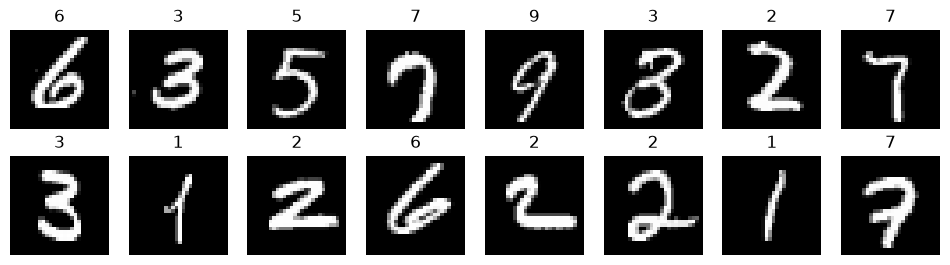

val class counts: [413 468 418 435 407 380 414 440 406 419]


In [15]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for ax, img, lbl in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(int(lbl)); ax.axis("off")
plt.show()

print("val class counts:", np.bincount(val_loader.dataset.labels.numpy()))